## Step 1: Import Libraries

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import (
    accuracy_score,
    top_k_accuracy_score,
    classification_report,
    confusion_matrix,
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
import lightgbm as lgb
from lightgbm import LGBMClassifier


## Step 2: Load Dataset

In [ ]:
train = pd.read_csv(r"C:\Users\Abhay\OneDrive\Desktop\AI-Fertilizer-Recommendation\data\train.csv")

# Feature engineering
train["total_npk"] = train["Nitrogen"] + train["Phosphorous"] + train["Potassium"]
train["n_p_ratio"] = train["Nitrogen"] / (train["Phosphorous"] + 1)
train["n_k_ratio"] = train["Nitrogen"] / (train["Potassium"] + 1)
train["p_k_ratio"] = train["Phosphorous"] / (train["Potassium"] + 1)
train["low_n"] = (train["Nitrogen"] < 60).astype(int)
train["low_p"] = (train["Phosphorous"] < 50).astype(int)
train["low_k"] = (train["Potassium"] < 50).astype(int)

print(train.shape)
train.head()


(750000, 17)


,id,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name,total_npk,n_p_ratio,n_k_ratio,p_k_ratio,low_n,low_p,low_k
0,0,37,70,36,Clayey,Sugarcane,36,4,5,28-28,45,6.000000,7.200000,1.000000,1,1,1
1,1,27,69,65,Sandy,Millets,30,6,18,28-28,54,1.578947,4.285714,2.571429,1,1,1
2,2,29,63,32,Sandy,Millets,24,12,16,17-17-17,52,1.411765,1.846154,1.230769,1,1,1
3,3,35,62,54,Sandy,Barley,39,12,4,10-26-26,55,7.800000,3.000000,0.307692,1,1,1
4,4,35,58,43,Red,Paddy,37,2,16,DAP,55,2.176471,12.333333,5.333333,1,1,1


## Step 3: Encode Data

In [ ]:
soil_encoder = LabelEncoder()
crop_encoder = LabelEncoder()
target_encoder = LabelEncoder()

train["Soil Type"] = soil_encoder.fit_transform(train["Soil Type"])
train["Crop Type"] = crop_encoder.fit_transform(train["Crop Type"])

train["Fertilizer Name"] = target_encoder.fit_transform(
    train["Fertilizer Name"]
)

# Step 4: Split Features and Target

In [ ]:
X = train.drop(["id", "Fertilizer Name"], axis=1)
print(X.columns.tolist())
y = train["Fertilizer Name"]


['Temparature', 'Humidity', 'Moisture', 'Soil Type', 'Crop Type', 'Nitrogen', 'Potassium', 'Phosphorous', 'total_npk', 'n_p_ratio', 'n_k_ratio', 'p_k_ratio', 'low_n', 'low_p', 'low_k']


## Step 5: Train-Test Split

In [ ]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

## Step 6: Train Logistic Regression

In [ ]:
lgbm = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.08,
    num_leaves=64,
    max_depth=12,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.7,
    random_state=42,
    n_jobs=-1,
)

lgbm.fit(
    X_train,
    y_train,
    eval_set=[(X_valid, y_valid)],
    eval_metric="multi_logloss",
    callbacks=[lgb.early_stopping(stopping_rounds=25), lgb.log_evaluation(period=50)],
)

pred = lgbm.predict(X_valid)
proba = lgbm.predict_proba(X_valid)

print("Accuracy:", accuracy_score(y_valid, pred))
print("Top-3 Accuracy:", top_k_accuracy_score(y_valid, proba, k=3))


C:\Users\Abhay\AppData\Roaming\Python\Python311\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.017236 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1060
[LightGBM] [Info] Number of data points in the train set: 600000, number of used features: 12
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Start training from score -1.884862
[LightGBM] [Info] Start training from score -1.880055
[LightGBM] [Info] Start training from score -1.897542
[LightGBM] [Info] Start training from score -1.911546
[LightGBM] [Info] Start training from score -1.909125
[LightGBM] [Info] Start training from score -2.067671
[LightGBM] [Info] Start training from score -2.094839
Training until validation scores don't improve for 25 rounds
[50]	valid_0's multi_logloss: 1.92822
[100]	valid_0's multi_logloss: 1.92535
[150]	valid_0's multi_logloss: 1.9

## Step 7: Decision Tree

In [ ]:
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_train, y_train)

pred = dt.predict(X_valid)

print("Accuracy:", accuracy_score(y_valid, pred))

Accuracy: 0.14946


In [ ]:
dt.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': 42,
 'splitter': 'best'}

## Step 8: Random Forest

In [ ]:
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(X_train, y_train)

pred = rf.predict(X_valid)

print("Accuracy:", accuracy_score(y_valid, pred))

Accuracy: 0.16831333333333334


In [ ]:
rf.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 200,
 'n_jobs': None,
 'oob_score': False,
 'random_state': 42,
 'verbose': 0,
 'warm_start': False}

## Step 9: Extra Trees

In [ ]:
from sklearn.ensemble import ExtraTreesClassifier

et = ExtraTreesClassifier(
    n_estimators=20,
    max_depth=15,
    random_state=42,
    n_jobs=1,
)

et.fit(X_train, y_train)

pred = et.predict(X_valid)

from sklearn.metrics import accuracy_score

print("Accuracy:", accuracy_score(y_valid, pred))

Accuracy: 0.17004


## Step 10: Compare Models

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=50,
        max_depth=12,
        random_state=42,
        n_jobs=1,
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=50,
        max_depth=12,
        random_state=42,
        n_jobs=1,
    ),
}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    pred = model.predict(X_valid)

    acc = accuracy_score(y_valid, pred)

    results.append([name, acc])

results = pd.DataFrame(results, columns=["Model", "Accuracy"])

results = results.sort_values(by="Accuracy", ascending=False)

## Step 11: Classification Report

In [ ]:
best_model = ExtraTreesClassifier(
    n_estimators=50,
    max_depth=12,
    random_state=42,
    n_jobs=1,
)

best_model.fit(X_train, y_train)

pred = best_model.predict(X_valid)

print(classification_report(y_valid, pred))

              precision    recall  f1-score   support

           0       0.17      0.27      0.21     22777
           1       0.17      0.39      0.24     22887
           2       0.18      0.19      0.18     22491
           3       0.17      0.12      0.14     22178
           4       0.17      0.17      0.17     22232
           5       0.20      0.01      0.02     18972
           6       0.17      0.00      0.01     18463

    accuracy                           0.17    150000
   macro avg       0.18      0.16      0.14    150000
weighted avg       0.18      0.17      0.15    150000



## Step 12: Confusion Matrix

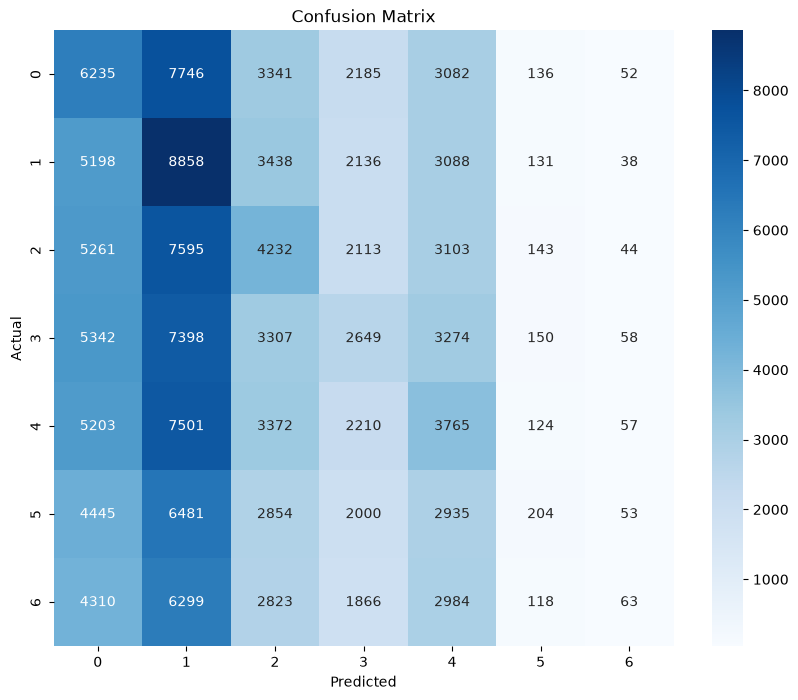

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_valid, pred)

plt.figure(figsize=(10,8))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

## Step 13: Feature Importance

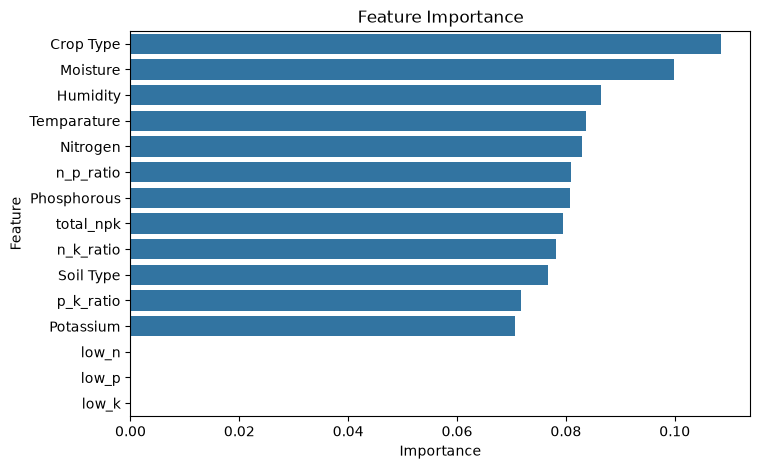

In [ ]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

importance

plt.figure(figsize=(8,5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance")

plt.show()